In [1]:
import pandas as pd 

In [2]:
import numpy as np 

In [3]:
import yfinance as yf 

In [4]:
import matplotlib.pyplot as plt

In [5]:
plt.rcParams.update({
    'figure.figsize': (12,6),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.linestyle':'--',
    'grid.alpha': 0.3,
    'axes.labelsize':11,
    'axes.titlesize': 14,
    'legend.frameon': False, 
    'font.size': 10})

In [6]:
Tickers = ('CAD=X', 'CL=F', 'EURUSD=X', 'GBPUSD=X', 'GC=F', 'DX-Y.NYB', 'AUDJPY=X', 'JPY=X', '^TNX', '^GSPC')
Data= pd.DataFrame()
for t in Tickers:
    Data[t] = yf.download(t, period ='5y', interval = '1d', auto_adjust=True)['Close']

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [7]:
Data

,CAD=X,CL=F,EURUSD=X,GBPUSD=X,GC=F,DX-Y.NYB,AUDJPY=X,JPY=X,^TNX,^GSPC
Date,,,,,,,,,,
2021-09-06,1.25303,NaN,1.188594,1.385925,NaN,NaN,81.709000,109.764000,NaN,NaN
2021-09-07,1.25343,68.349998,1.187507,1.383949,1795.900024,92.519997,81.664001,109.820000,1.370,4520.029785
2021-09-08,1.26464,69.300003,1.184357,1.377980,1790.699951,92.650002,81.466003,110.295998,1.334,4514.069824
2021-09-09,1.26940,68.139999,1.181910,1.376766,1797.400024,92.480003,81.134003,110.218002,1.299,4493.279785
2021-09-10,1.26626,69.720001,1.182592,1.383968,1789.599976,92.580002,80.879997,109.780998,1.341,4458.580078
...,...,...,...,...,...,...,...,...,...,...
2026-08-31,1.38991,85.760002,1.158896,1.354041,4431.100098,99.430000,114.637001,160.121994,4.758,7686.140137
2026-09-01,1.38510,90.220001,1.161764,1.355014,4348.000000,99.669998,114.542999,159.746994,4.796,7631.470215
2026-09-02,1.38941,91.010002,1.159555,1.351534,4366.299805,99.559998,114.488998,160.195999,4.796,7666.600098


In [8]:
Data = Data.rename(columns={'CAD=X':'USDCAD',
                           'CL=F': 'WTI',
                           'EURUSD=X':'EURUSD',
                           'GBPUSD=X':'GBPUSD',
                           'GC=F':'GOLD',
                           'DX-Y.NYB':'DXY',
                           'AUDJPY=X':'AUDJPY',
                           'JPY=X':'USDJPY',
                           '^TNX':'US10Y',
                           '^GSPC':'SP500'})

In [9]:
Data

,USDCAD,WTI,EURUSD,GBPUSD,GOLD,DXY,AUDJPY,USDJPY,US10Y,SP500
Date,,,,,,,,,,
2021-09-06,1.25303,NaN,1.188594,1.385925,NaN,NaN,81.709000,109.764000,NaN,NaN
2021-09-07,1.25343,68.349998,1.187507,1.383949,1795.900024,92.519997,81.664001,109.820000,1.370,4520.029785
2021-09-08,1.26464,69.300003,1.184357,1.377980,1790.699951,92.650002,81.466003,110.295998,1.334,4514.069824
2021-09-09,1.26940,68.139999,1.181910,1.376766,1797.400024,92.480003,81.134003,110.218002,1.299,4493.279785
2021-09-10,1.26626,69.720001,1.182592,1.383968,1789.599976,92.580002,80.879997,109.780998,1.341,4458.580078
...,...,...,...,...,...,...,...,...,...,...
2026-08-31,1.38991,85.760002,1.158896,1.354041,4431.100098,99.430000,114.637001,160.121994,4.758,7686.140137
2026-09-01,1.38510,90.220001,1.161764,1.355014,4348.000000,99.669998,114.542999,159.746994,4.796,7631.470215
2026-09-02,1.38941,91.010002,1.159555,1.351534,4366.299805,99.559998,114.488998,160.195999,4.796,7666.600098


In [10]:
Data1 = Data[['USDCAD', 'WTI', 'EURUSD', 'GBPUSD', 'GOLD', 'DXY', 'AUDJPY', 'USDJPY', 'SP500']]

In [11]:
Data2 = Data['US10Y']

In [12]:
SROR = Data1.pct_change().dropna()

In [13]:
LROR = Data2.diff().dropna()

# GOLD vs DOllar 

In [14]:
Rolling_corr20 = SROR['GOLD'].rolling (20).corr(SROR['DXY'])

In [15]:
Rolling_corr60 = SROR['GOLD'].rolling(60).corr(SROR['DXY'])

In [32]:
GD_mean60 = Rolling_corr60.mean()

In [39]:
GD_absmean60 = Rolling_corr60.abs().mean()

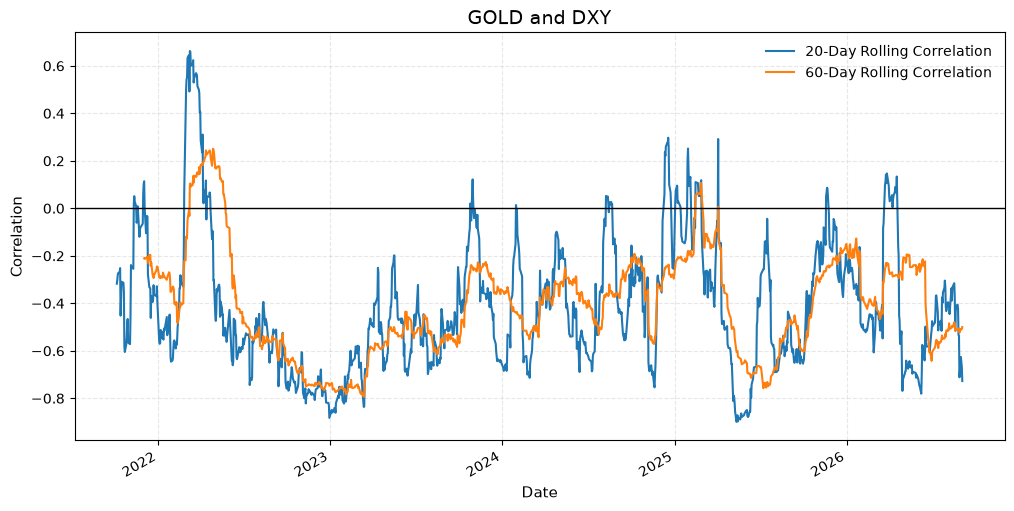

In [16]:
fig, ax = plt.subplots()

Rolling_corr20.plot(
    ax=ax,
    label="20-Day Rolling Correlation"
)

Rolling_corr60.plot(
    ax=ax,
    label="60-Day Rolling Correlation"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("GOLD and DXY")
ax.set_ylabel("Correlation")
ax.legend()

fig.savefig(
    "GOLD_DXY.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
        

# GOLD vs US10Y

In [17]:
GYR_corr20 = SROR['GOLD'].rolling(20).corr(LROR)

In [18]:
GYR_corr60 = SROR['GOLD'].rolling(60).corr(LROR)

In [33]:
GYR_mean60= GYR_corr60.mean()

In [40]:
GYR_absmean60 = GYR_corr60.abs().mean()

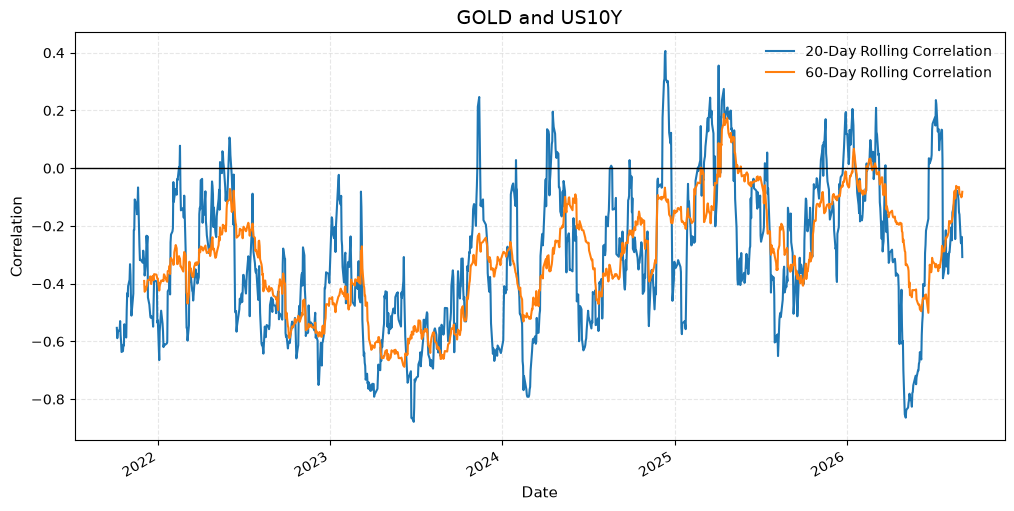

In [19]:
fig, ax = plt.subplots()

GYR_corr20.plot(
    ax=ax,
    label="20-Day Rolling Correlation"
)

GYR_corr60.plot(
    ax=ax,
    label="60-Day Rolling Correlation"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("GOLD and US10Y")
ax.set_ylabel("Correlation")
ax.legend()

fig.savefig(
    "GOLD_US10Y.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# EURUSD vs GBPUSD

In [20]:
EG_corr20 = SROR['EURUSD'].rolling(20).corr(SROR['GBPUSD'])

In [21]:
EG_corr60 = SROR['EURUSD'].rolling(60).corr(SROR['GBPUSD'])

In [34]:
EG_mean60 = EG_corr60.mean()

In [41]:
EG_absmean60 = EG_corr60.abs().mean()

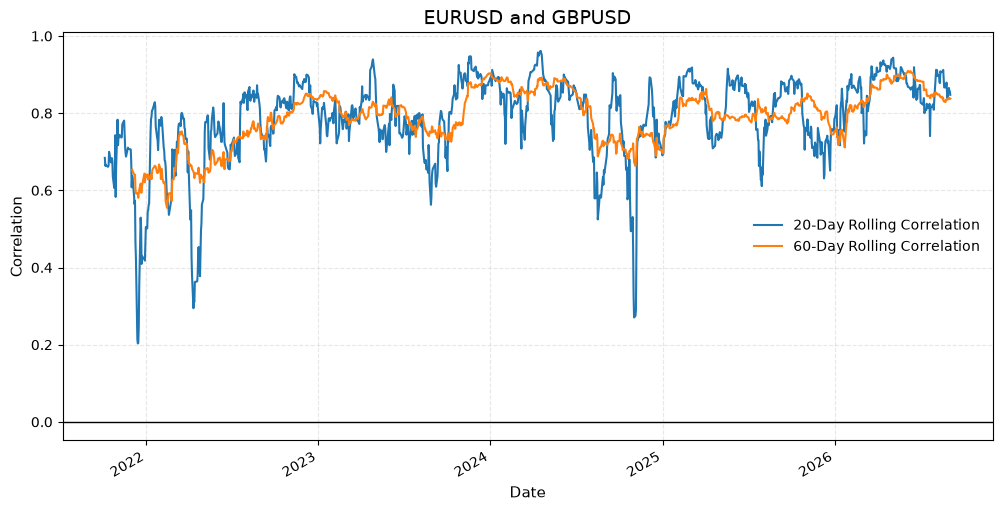

In [22]:
fig, ax = plt.subplots()

EG_corr20.plot(
    ax=ax,
    label="20-Day Rolling Correlation"
)

EG_corr60.plot(
    ax=ax,
    label="60-Day Rolling Correlation"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("EURUSD and GBPUSD")
ax.set_ylabel("Correlation")
ax.legend()

fig.savefig(
    "EURUSD_GBPUSD.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# DXY vs SP500

In [23]:
DSP_corr20 = SROR['DXY'].rolling(20).corr(SROR['SP500'])

In [24]:
DSP_corr60 = SROR['DXY'].rolling(60).corr(SROR['SP500'])

In [35]:
DSP_mean60 = DSP_corr60.mean()

In [42]:
DSP_absmean60 = DSP_corr60.abs().mean()

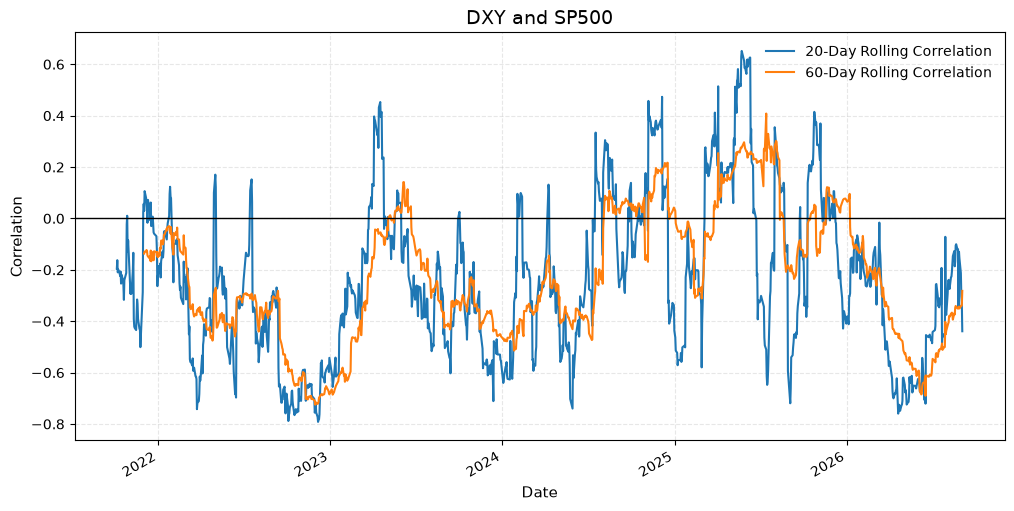

In [25]:
fig, ax = plt.subplots()

DSP_corr20.plot(
    ax=ax,
    label="20-Day Rolling Correlation"
)

DSP_corr60.plot(
    ax=ax,
    label="60-Day Rolling Correlation"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("DXY and SP500")
ax.set_ylabel("Correlation")
ax.legend()

fig.savefig(
    "DXY_SP500.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# AUDJPY vs SP500

In [26]:
ASP_corr20 = SROR['AUDJPY'].rolling(20).corr(SROR['SP500'])

In [27]:
ASP_corr60 = SROR['AUDJPY'].rolling(60).corr(SROR['SP500'])

In [36]:
ASP_mean60 = ASP_corr60.mean()

In [43]:
ASP_absmean60 = ASP_corr60.abs().mean()

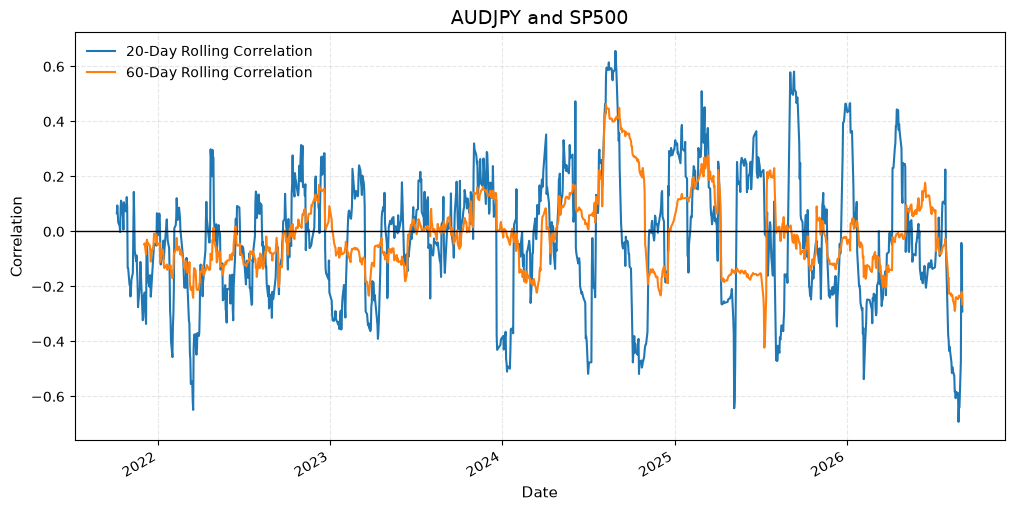

In [28]:
fig, ax = plt.subplots()

ASP_corr20.plot(
    ax=ax,
    label="20-Day Rolling Correlation"
)

ASP_corr60.plot(
    ax=ax,
    label="60-Day Rolling Correlation"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("AUDJPY and SP500")
ax.set_ylabel("Correlation")
ax.legend()

fig.savefig(
    "AUDJPY_SP500.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# USDJPY vs US10Y

In [29]:
UST_corr20 = SROR['USDJPY'].rolling(20).corr(LROR)

In [30]:
UST_corr60 = SROR['USDJPY'].rolling(60).corr(LROR)

In [37]:
UST_mean60 = UST_corr60.mean()

In [44]:
UST_absmean60 = UST_corr60.abs().mean()

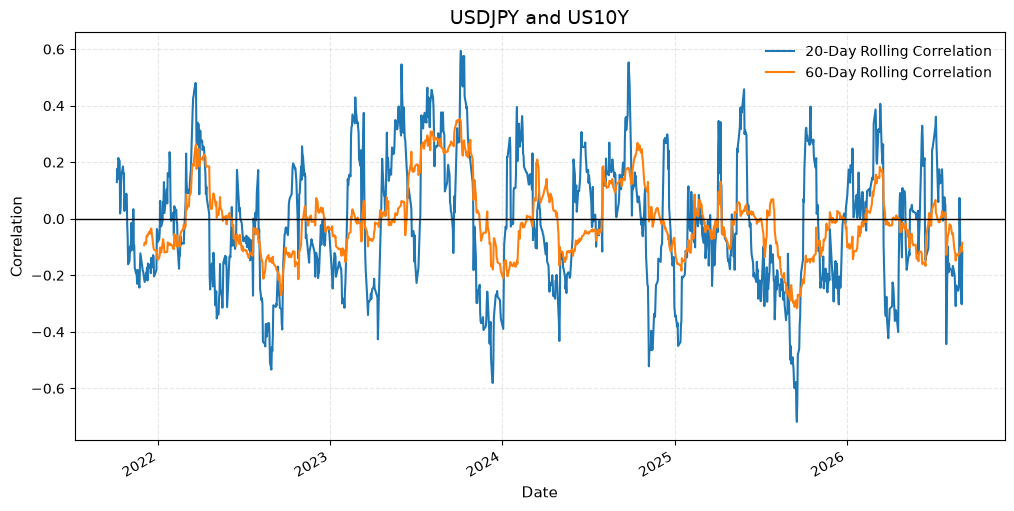

In [31]:
fig, ax = plt.subplots()

UST_corr20.plot(
    ax=ax,
    label="20-Day Rolling Correlation"
)

UST_corr60.plot(
    ax=ax,
    label="60-Day Rolling Correlation"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("USDJPY and US10Y")
ax.set_ylabel("Correlation")
ax.legend()

fig.savefig(
    "USDJPY_US10Y.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
MEAN_60D = pd.Series({
    "Gold vs DXY": GD_mean60,
    "Gold vs US10Y": GYR_mean60,
    "EURUSD vs GBPUSD": EG_mean60,
    "DXY vs SP500": DSP_mean60,
    "AUDJPY vs SP500": ASP_mean60,
    "USDJPY vs US10Y": UST_mean60
})

MEAN_60D.round(2)

Gold vs DXY        -0.41
Gold vs US10Y      -0.31
EURUSD vs GBPUSD    0.79
DXY vs SP500       -0.23
AUDJPY vs SP500    -0.01
USDJPY vs US10Y    -0.01
dtype: float64

In [45]:
MEAN_ABSOLUTE_60D = pd.Series({
    "Gold vs DXY": GD_absmean60,
    "Gold vs US10Y": GYR_absmean60,
    "EURUSD vs GBPUSD": EG_absmean60,
    "DXY vs SP500": DSP_absmean60,
    "AUDJPY vs SP500": ASP_absmean60,
    "USDJPY vs US10Y": UST_absmean60
})

MEAN_ABSOLUTE_60D.sort_values(ascending=False).round(2)

EURUSD vs GBPUSD    0.79
Gold vs DXY         0.42
Gold vs US10Y       0.31
DXY vs SP500        0.28
AUDJPY vs SP500     0.11
USDJPY vs US10Y     0.10
dtype: float64

In [62]:
CORRELATION_60D = pd.DataFrame({
    "Gold vs DXY": Rolling_corr60,
    "Gold vs US10Y": GYR_corr60,
    "EURUSD vs GBPUSD": EG_corr60,
    "DXY vs SP500": DSP_corr60,
    "AUDJPY vs SP500": ASP_corr60,
    "USDJPY vs US10Y": UST_corr60
})

In [61]:
LATEST_60D = pd.Series({
    "Gold vs DXY": Rolling_corr60.iloc[-1],
    "Gold vs US10Y": GYR_corr60.iloc[-1],
    "EURUSD vs GBPUSD": EG_corr60.iloc[-1],
    "DXY vs SP500": DSP_corr60.iloc[-1],
    "AUDJPY vs SP500": ASP_corr60.iloc[-1],
    "USDJPY vs US10Y": UST_corr60.iloc[-1]
})

In [63]:
SUMMARY = pd.DataFrame({
    "Mean Correlation": CORRELATION_60D.mean(),
    "Mean Absolute Correlation": CORRELATION_60D.abs().mean(),
    "Latest Correlation": CORRELATION_60D.iloc[-1]
})

SUMMARY = SUMMARY.sort_values(
    "Mean Absolute Correlation",
    ascending=False
)

SUMMARY.round(2)

,Mean Correlation,Mean Absolute Correlation,Latest Correlation
EURUSD vs GBPUSD,0.79,0.79,0.84
Gold vs DXY,-0.41,0.42,-0.50
Gold vs US10Y,-0.31,0.31,-0.08
DXY vs SP500,-0.23,0.28,-0.28
AUDJPY vs SP500,-0.01,0.11,-0.26
USDJPY vs US10Y,-0.01,0.10,-0.08


# Directional Consistency

In [48]:
GOLD_DXY_CONSISTENCY = (
    Rolling_corr60.dropna() < 0
).mean() * 100

In [49]:
EURUSD_GBPUSD_CONSISTENCY = (
    EG_corr60.dropna() > 0
).mean() * 100

In [50]:
GOLD_US10Y_CONSISTENCY = (
    GYR_corr60.dropna()< 0
).mean() * 100

In [51]:
SP500_DXY_CONSISTENCY = (
    DSP_corr60.dropna()<0
).mean() * 100

In [52]:
AUDJPY_SP500_CONSISTENCY = (
    ASP_corr60.dropna()>0
).mean() * 100

In [53]:
USDJPY_US10Y_CONSISTENCY = (
    UST_corr60.dropna()>0
).mean() * 100

In [64]:
DIRECTIONAL_CONSISTENCY = pd.Series({
    "Gold vs DXY": GOLD_DXY_CONSISTENCY,
    "Gold vs US10Y": GOLD_US10Y_CONSISTENCY,
    "EURUSD vs GBPUSD": EURUSD_GBPUSD_CONSISTENCY,
    "DXY vs SP500": SP500_DXY_CONSISTENCY,
    "AUDJPY vs SP500": AUDJPY_SP500_CONSISTENCY,
    "USDJPY vs US10Y": USDJPY_US10Y_CONSISTENCY
})

DIRECTIONAL_CONSISTENCY.sort_values(
    ascending=False
).round(2)

EURUSD vs GBPUSD    100.00
Gold vs US10Y        96.34
Gold vs DXY          94.60
DXY vs SP500         77.53
USDJPY vs US10Y      41.11
AUDJPY vs SP500      40.24
dtype: float64

In [65]:
FINAL_SUMMARY = pd.DataFrame({
    "Mean Correlation": MEAN_60D,
    "Mean Absolute Correlation": MEAN_ABSOLUTE_60D,
    "Directional Consistency (%)": DIRECTIONAL_CONSISTENCY,
    "Latest 60-Day Correlation": LATEST_60D
})

FINAL_SUMMARY = FINAL_SUMMARY.sort_values(
    "Mean Absolute Correlation",
    ascending=False
)

FINAL_SUMMARY.round(2)

,Mean Correlation,Mean Absolute Correlation,Directional Consistency (%),Latest 60-Day Correlation
EURUSD vs GBPUSD,0.79,0.79,100.00,0.84
Gold vs DXY,-0.41,0.42,94.60,-0.50
Gold vs US10Y,-0.31,0.31,96.34,-0.08
DXY vs SP500,-0.23,0.28,77.53,-0.28
AUDJPY vs SP500,-0.01,0.11,40.24,-0.26
USDJPY vs US10Y,-0.01,0.10,41.11,-0.08
